# Финальный проект: post-earnings drift

### Выполнили: Туровинин Никита, Яблоков Артем, Федосов Александр (группа 4)

## Часть 1. Данные (40 баллов)

Берем три компании из разных отраслей: AAPL (tech), JNJ (healthcare), CAT (industrials). Период: 2021-01-01 до 2025-06-01.

Для каждого отчета нужны три вещи: текст earnings call, EPS surprise и цены акции вокруг даты отчета. Label считается как доходность за 3-5 торговых дней после отчета.

In [28]:
# !pip install yfinance duckdb pyarrow scikit-learn "transformers==4.40.2" torch -q

In [29]:
import json, re
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

TICKERS = {"AAPL": "Technology", "JNJ": "Healthcare", "CAT": "Industrials"}
START, END = "2021-01-01", "2025-06-01"
VER = "v8"

DATA_DIR = Path("data")
(DATA_DIR / "transcripts").mkdir(parents=True, exist_ok=True)

### 1.1. Транскрипты earnings calls

Сначала пробовали FMP и API Ninjas, но на доступном нам доступе транскрипты нормально не получили. Поэтому берем открытый датасет [defeatbeta/yahoo-finance-data](https://huggingface.co/datasets/defeatbeta/yahoo-finance-data) с earnings call transcripts из Yahoo Finance. Каждый transcript сохраняем отдельно с ticker, кварталом и датой звонка

ChatGPT помог с технической частью: подсказал вариант с duckdb + httpfs, чтобы читать parquet прямо с Hugging Face.

In [30]:
HF_URL = ("https://huggingface.co/datasets/defeatbeta/yahoo-finance-data/"
          "resolve/main/data/stock_earning_call_transcripts.parquet")

# качаем только тикеры, которых нет в кэше
have = {p.name.split("_")[0] for p in (DATA_DIR / "transcripts").glob("*.json")}
need = [t for t in TICKERS if t not in have]

if need:
    con = duckdb.connect()
    # httpfs нужен, чтобы duckdb читал parquet по ссылке
    con.execute("INSTALL httpfs; LOAD httpfs;")
    tickers_sql = ",".join(f"'{t}'" for t in need)
    raw = con.execute(f"""
        SELECT symbol, fiscal_year, fiscal_quarter, report_date, transcripts
        FROM '{HF_URL}' WHERE symbol IN ({tickers_sql})
    """).df()
    con.close()
    for _, r in raw.iterrows():
        text = "\n".join(f"{p['speaker']}: {p['content']}" for p in r.transcripts)
        path = DATA_DIR / "transcripts" / f"{r.symbol}_{r.fiscal_year}Q{r.fiscal_quarter}.json"
        path.write_text(json.dumps({
            "ticker": r.symbol, "fiscal_year": int(r.fiscal_year),
            "fiscal_quarter": int(r.fiscal_quarter),
            "date": str(r.report_date), "content": text}))
    print("скачано:", len(raw))
else:
    print("кэш уже есть")

кэш уже есть


In [31]:
rows = []
for p in sorted((DATA_DIR / "transcripts").glob("*.json")):
    rec = json.loads(p.read_text())
    rows.append({"ticker": rec["ticker"],
                 "fiscal_period": f"{rec['fiscal_year']}Q{rec['fiscal_quarter']}",
                 "call_date": pd.to_datetime(rec["date"][:10]),
                 "transcript": rec["content"]})

df_tr = (pd.DataFrame(rows)
         .query("@START <= call_date <= @END")
         .drop_duplicates(["ticker", "call_date"])
         .sort_values(["ticker", "call_date"]).reset_index(drop=True))
print(df_tr.groupby("ticker").size())

ticker
AAPL    18
CAT     18
JNJ     18
dtype: int64


Получается по 18 транскриптов инвесторских звонков на каждую компанию. Этого хватает под требование задания в 14-16 кварталов на компанию, у нас немного больше из-за границ периода и доступных дат

### 1.2. EPS surprise

Из yfinance берем consensus EPS estimate, actual EPS и время публикации отчета. Surprise считаем как `(actual - estimate) / |estimate|`. BMO/AMC нужны дальше для label, потому что рынок реагирует в разные торговые дни.

In [32]:
EPS_CACHE = DATA_DIR / f"eps_surprises_{VER}.csv"
LEGACY_PREVIEW = DATA_DIR / f"master_dataset_preview_{VER}.csv"


def eps_from_legacy_preview():
    if not LEGACY_PREVIEW.exists():
        raise FileNotFoundError(
            "Yahoo Finance не ответил, и локальный preview не найден. "
            "Нужно запустить сбор данных с интернетом или положить кэш рядом с ноутбуком."
        )
    df = pd.read_csv(LEGACY_PREVIEW, parse_dates=["earn_date"])
    cols = ["ticker", "earn_date", "is_bmo", "eps_estimate", "eps_actual", "surprise_pct", "beat"]
    df = df.loc[df.ticker.isin(TICKERS), cols].drop_duplicates(["ticker", "earn_date"])
    return df.query("@START <= earn_date <= @END")


def get_eps(ticker):
    df = yf.Ticker(ticker).get_earnings_dates(limit=40).reset_index()

    # yfinance иногда меняет названия колонок, поэтому ищем их по смыслу
    rename = {}
    for col in df.columns:
        low = str(col).lower()
        if low in {"earnings date", "earnings_date", "earn_ts"}:
            rename[col] = "earn_ts"
        elif "estimate" in low:
            rename[col] = "eps_estimate"
        elif "reported" in low or "actual" in low:
            rename[col] = "eps_actual"
    df = df.rename(columns=rename)

    needed = {"earn_ts", "eps_estimate", "eps_actual"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Неожиданные колонки yfinance для {ticker}: {list(df.columns)}")

    df = df.dropna(subset=["eps_estimate", "eps_actual"])
    df["ticker"] = ticker
    df["earn_ts"] = pd.to_datetime(df["earn_ts"])
    df["is_bmo"] = df.earn_ts.dt.hour < 12
    df["earn_date"] = df.earn_ts.dt.tz_localize(None).dt.normalize()
    df["surprise_pct"] = (df.eps_actual - df.eps_estimate) / df.eps_estimate.abs()
    df["beat"] = (df.eps_actual > df.eps_estimate).astype(int)
    return df.query("@START <= earn_date <= @END")[
        ["ticker", "earn_date", "is_bmo", "eps_estimate", "eps_actual", "surprise_pct", "beat"]]


if EPS_CACHE.exists():
    df_eps = pd.read_csv(EPS_CACHE, parse_dates=["earn_date"])
    print("EPS из кэша:", EPS_CACHE)
else:
    try:
        df_eps = (pd.concat([get_eps(t) for t in TICKERS], ignore_index=True)
                  .sort_values(["ticker", "earn_date"]).reset_index(drop=True))
        df_eps.to_csv(EPS_CACHE, index=False)
        print("EPS скачаны из yfinance и сохранены:", EPS_CACHE)
    except Exception as e:
        print("yfinance по EPS не ответил, берем локальный preview:", type(e).__name__, str(e))
        df_eps = (eps_from_legacy_preview()
                  .sort_values(["ticker", "earn_date"]).reset_index(drop=True))
        df_eps.to_csv(EPS_CACHE, index=False)
        print("EPS восстановлены из локального preview:", EPS_CACHE)

print(df_eps.groupby("ticker").size())
df_eps.head()

EPS из кэша: data\eps_surprises_v8.csv
ticker
AAPL    18
CAT     18
JNJ     18
dtype: int64


,ticker,earn_date,is_bmo,eps_estimate,eps_actual,surprise_pct,beat
0,AAPL,2021-01-27,False,1.42,1.68,0.183099,1
1,AAPL,2021-04-28,False,0.98,1.40,0.428571,1
2,AAPL,2021-07-27,False,1.01,1.30,0.287129,1
3,AAPL,2021-10-28,False,1.24,1.24,0.000000,0
4,AAPL,2022-01-27,False,1.89,2.10,0.111111,1


Здесь тоже получилось по 18 отчетов на AAPL, CAT и JNJ, по числу наблюдений ничего не потеряли. Из EPS-таблицы потом берем `surprise_pct`, а `is_bmo` понадобится при расчете label

### 1.3. Цены и label

Если отчет вышел после закрытия (AMC), рынок реагирует со следующего торгового дня T. Если до открытия (BMO), то в тот же день. База это закрытие последнего дня строго до T, то есть последняя цена без информации из отчета.

`ret_k = Close(T + k - 1) / Close(base) - 1`, k = 3 и 5. В признаки ничего из окна T..T+5 не попадает, поэтому look-ahead bias здесь исключен.

In [33]:
PRICE_CACHE = DATA_DIR / f"prices_{VER}.parquet"

if PRICE_CACHE.exists():
    prices = pd.read_parquet(PRICE_CACHE)
    prices.index = pd.to_datetime(prices.index)
    print("цены из кэша:", PRICE_CACHE)
else:
    try:
        prices = yf.download(list(TICKERS), start="2020-09-01", end="2025-06-20",
                             auto_adjust=True, progress=False, threads=False)["Close"]
        if prices.empty:
            raise ValueError("yfinance вернул пустую таблицу цен")
        prices.to_parquet(PRICE_CACHE)
        print("цены скачаны из yfinance и сохранены:", PRICE_CACHE)
    except Exception as e:
        if LEGACY_PREVIEW.exists():
            print("yfinance по ценам не ответил, берем labels из локального preview:",
                  type(e).__name__, str(e))
            cached = pd.read_csv(LEGACY_PREVIEW, parse_dates=["earn_date", "base_day", "reaction_day"])
            df_lab = cached[["ticker", "earn_date", "is_bmo", "eps_estimate", "eps_actual",
                             "surprise_pct", "beat", "base_day", "reaction_day", "ret_3d", "ret_5d"]]
            df_lab = df_lab.query("ticker in @TICKERS and @START <= earn_date <= @END").reset_index(drop=True)
            prices = None
        else:
            raise

# BMO и AMC сдвигают первый день реакции по-разному
def post_earnings_returns(ticker, earn_date, is_bmo, ks=(3, 5)):
    s = prices[ticker].dropna()
    days = s.index
    after = days[days >= earn_date] if is_bmo else days[days > earn_date]
    if len(after) == 0:
        return None
    i = days.get_loc(after[0])
    if i == 0:
        return None
    # base_day это день до реакции рынка
    out = {"reaction_day": after[0], "base_day": days[i-1], "base_close": float(s.iloc[i-1])}
    for k in ks:
        out[f"ret_{k}d"] = float(s.iloc[i+k-1] / s.iloc[i-1] - 1) if i+k-1 < len(s) else np.nan
    return out

if prices is not None:
    labels = df_eps.apply(lambda r: post_earnings_returns(r.ticker, r.earn_date, r.is_bmo), axis=1)
    df_lab = pd.concat([df_eps.reset_index(drop=True), pd.DataFrame(list(labels))], axis=1).dropna(subset=["ret_5d"])

print(len(df_lab), "отчетов с label")

цены из кэша: data\prices_v8.parquet
54 отчетов с label


После расчета label осталось 54 отчета, как раз 18 на каждую компанию.

### 1.4. Склейка транскриптов с EPS и label

Дата звонка и дата отчета могут расходиться на день, поэтому мержим по ближайшей дате (допуск 4 дня) внутри тикера.

(чат помог с функцией pd.merge_asof)

In [34]:
# мержим по ближайшей дате
master = pd.merge_asof( df_tr.sort_values("call_date"), df_lab.sort_values("earn_date"),
    left_on="call_date", right_on="earn_date", by="ticker",
    direction="nearest", tolerance=pd.Timedelta("4D"))

lost = master[master.earn_date.isna()]
if len(lost):
    print("не сматчились:")
    print(lost[["ticker", "fiscal_period", "call_date"]])
master = master.dropna(subset=["earn_date"]).reset_index(drop=True)
assert master.duplicated(["ticker", "earn_date"]).sum() == 0  # один отчет не должен попасть два раза
print(master.groupby("ticker").size())

ticker
AAPL    18
CAT     18
JNJ     18
dtype: int64


Transcripts, EPS surprise и цены сошлись без потери отчетов.

### 1.5. Препроцессинг текста

Делим на prepared remarks и Q&A. Q&A начинается с первой реплики оператора не в самом начале звонка, потому что в начале оператор просто открывает звонок. Из текста убираем реплики оператора и лишние пробелы.

In [35]:
def split_transcript(text):
    lines = text.split("\n")
    
    # первую реплику от "operator" в начале не считаем началом Q&A
    op = [i for i in range(1, len(lines)) if lines[i].lower().startswith("operator:")]
    withq = [i for i in op if "question" in lines[i].lower()]
    cut = withq[0] if withq else (op[0] if op else None)
    if cut is None:
        return text, ""
    return "\n".join(lines[:cut]), "\n".join(lines[cut:])

# убираем служебные строки operator
def clean_text(text):
    text = re.sub(r"^\s*operator:.*?$", " ", text, flags=re.I | re.M)
    return re.sub(r"\s+", " ", text).strip()

parts = master.transcript.apply(split_transcript)
master["prepared_text"] = parts.str[0].apply(clean_text)
master["qa_text"] = parts.str[1].apply(clean_text)
master["n_words_prepared"] = master.prepared_text.str.split().str.len()
master["n_words_qa"] = master.qa_text.str.split().str.len()

print("строк без Q&A:", (master.n_words_qa == 0).sum())
master[["ticker", "call_date", "n_words_prepared", "n_words_qa"]].head()

строк без Q&A: 0


,ticker,call_date,n_words_prepared,n_words_qa
0,JNJ,2021-01-26,6752,5343
1,AAPL,2021-01-27,3222,4911
2,CAT,2021-01-29,4897,3882
3,JNJ,2021-04-20,5089,5655
4,AAPL,2021-04-28,3291,4788


Q&A нашли во всех 54 транскриптах, дальше можно считать sentiment отдельно для prepared remarks и Q&A

### 1.6. Финальный датасет

Собираем одну таблицу для модели: компания, отрасль, даты, EPS surprise, доходности после отчета и две части transcript. Полные тексты сохраняем в parquet, а отдельный preview без текстов сохраняем в csv, чтобы было удобнее смотреть таблицу.

In [36]:
master["industry"] = master.ticker.map(TICKERS)
final = master[["industry", "ticker", "fiscal_period", "call_date", "earn_date", "is_bmo",
                "eps_estimate", "eps_actual", "surprise_pct", "beat",
                "base_day", "reaction_day", "ret_3d", "ret_5d",
                "prepared_text", "qa_text", "n_words_prepared", "n_words_qa"]]

assert (final.base_day < final.reaction_day).all()      # нет look-ahead
assert final[["surprise_pct", "ret_3d", "ret_5d"]].notna().all().all()
final.to_parquet(DATA_DIR / f"master_dataset_{VER}.parquet", index=False) # полный датасет с текстами и preview без длинных текстов

final.drop(columns=["prepared_text", "qa_text"]).to_csv(DATA_DIR / f"master_dataset_preview_{VER}.csv", index=False)
print("сохранено, строк:", len(final))

сохранено, строк: 54


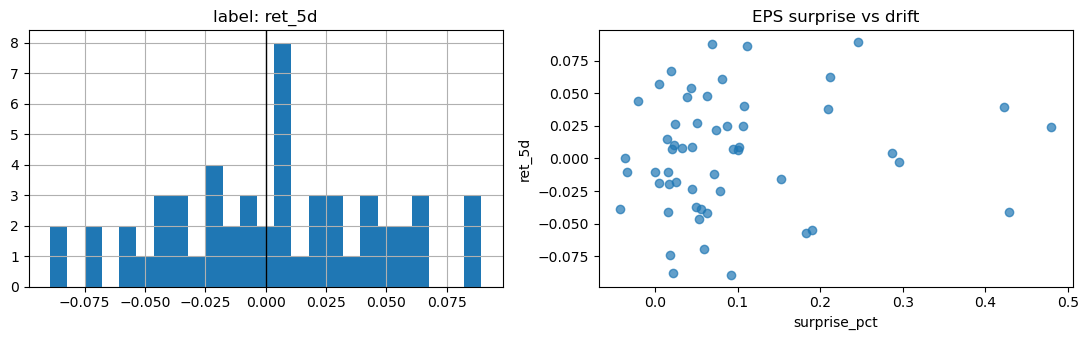

,mean,count
beat,,
0,-0.003113,5
1,0.003614,49


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
final.ret_5d.hist(bins=25, ax=axes[0])
axes[0].axvline(0, color="k", lw=1)
axes[0].set_title("label: ret_5d")
axes[1].scatter(final.surprise_pct.clip(-1, 1), final.ret_5d, alpha=0.7)
axes[1].set_xlabel("surprise_pct"); axes[1].set_ylabel("ret_5d")
axes[1].set_title("EPS surprise vs drift")
plt.tight_layout(); plt.show()

final.groupby("beat")["ret_5d"].agg(["mean", "count"])

`ret_5d` это доходность акции за 5 торговых дней после отчета. По графику видно, что были и положительные, и отрицательные реакции, поэтому дальше можно предсказывать направление движения после отчета.

`beat` означает, что actual EPS оказался выше consensus estimate. Таких случаев 49 из 54, поэтому `beat` сам по себе почти не разделяет данные. Поэтому дальше используем `surprise_pct`, он показывает не просто beat/no beat, а насколько сильно факт отличался от прогноза.

## Часть 2. Архитектура

FinBERT используем как готовую модель для сентимента, он превращает транскрипт в значение. Потом добавляем EPS surprise и momentum и обучаем маленький классификатор, который предсказывает, будет ли `ret_5d > 0`.

In [38]:
import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

df = final.copy().sort_values("earn_date").reset_index(drop=True)
print(len(df), "отчетов")

54 отчетов


### 2.1. Sentiment через FinBERT

Transcript длиннее лимита BERT, поэтому режем его на чанки по 200 слов. Каждый чанк скорим через FinBERT, потом усредняем `p_pos - p_neg`.

Prepared remarks и Q&A скорим отдельно, потому что это разные части call: сначала менеджмент читает заготовленный текст, потом отвечает на вопросы аналитиков.

In [39]:
# режем transcript на куски под лимит BERT
def chunk_text(text, size=200):
    words = text.split()
    return [" ".join(words[i:i+size]) for i in range(0, len(words), size)]


# создаем FinBERT pipeline, GPU используется если есть
def build_finbert():
    from transformers import pipeline
    device = 0 if torch.cuda.is_available() else -1
    return pipeline("sentiment-analysis", model="ProsusAI/finbert",
                    device=device, top_k=None, truncation=True, max_length=512)


# score = positive - negative
def sentiment_score(text):
    if len(text.split()) < 10:
        return np.nan
    global finbert
    if "finbert" not in globals():
        finbert = build_finbert()
    chunks = chunk_text(text)
    scores = []
    for out in finbert(chunks, batch_size=16):
        p = {d["label"]: d["score"] for d in out}
        scores.append(p["positive"] - p["negative"])
    return float(np.mean(scores))

In [40]:
%%time
# считаем один раз и кэшируем
SENT_CACHE = DATA_DIR / f"sentiment_cache_{VER}.csv"
LEGACY_SENT_CACHE = Path("sentiment_cache.csv")

if SENT_CACHE.exists():
    sent = pd.read_csv(SENT_CACHE)
elif LEGACY_SENT_CACHE.exists():
    sent = pd.read_csv(LEGACY_SENT_CACHE)
    sent.to_csv(SENT_CACHE, index=False)
else:
    sent = pd.DataFrame({
        "sent_prepared": df.prepared_text.apply(sentiment_score),
        "sent_qa": df.qa_text.apply(sentiment_score),
    })
    sent.to_csv(SENT_CACHE, index=False)

if len(sent) != len(df):
    raise ValueError(f"В sentiment cache {len(sent)} строк, ожидали {len(df)}")

df["sent_prepared"] = sent.sent_prepared.values
df["sent_qa"] = sent.sent_qa.values
# у пары звонков одна из секций почти пустая - подставляем скор другой секции
df["sent_prepared"] = df.sent_prepared.fillna(df.sent_qa)
df["sent_qa"] = df.sent_qa.fillna(df.sent_prepared)
df[["ticker", "fiscal_period", "sent_prepared", "sent_qa"]].head()

CPU times: total: 15.6 ms
Wall time: 5.08 ms


,ticker,fiscal_period,sent_prepared,sent_qa
0,JNJ,2020Q4,0.162216,0.389325
1,AAPL,2021Q1,0.605425,0.287130
2,CAT,2020Q4,-0.023524,0.362144
3,JNJ,2021Q1,0.510896,0.578585
4,AAPL,2021Q2,0.577162,0.297161


### 2.2. Momentum до отчета

Доходность за 21 торговый день до базового дня. Считается только по ценам ДО отчета, так что look-ahead нет.

In [41]:
def momentum(ticker, base_day, lookback=21):
    s = prices[ticker].dropna()
    i = s.index.get_loc(base_day)
    return float(s.iloc[i] / s.iloc[i - lookback] - 1)

df["momentum"] = df.apply(lambda r: momentum(r.ticker, r.base_day), axis=1)
assert df.momentum.notna().all()
print("momentum посчитан:", df.momentum.notna().sum())

momentum посчитан: 54


### 2.3. Признаки, label и временной сплит

В модель идут четыре признака: `sent_prepared`, `sent_qa`, `surprise_pct`, `momentum`.

Label: `UP = 1`, если `ret_5d > 0`, иначе `UP = 0`.

Сплит делаем по времени: ранние отчеты в train, поздние в test

In [42]:
# признаки для модели
FEATURES = ["sent_prepared", "sent_qa", "surprise_pct", "momentum"]
df["y"] = (df.ret_5d > 0).astype(int)

# последние 25% отчетов оставляем на test
split_date = df.earn_date.quantile(0.75)
train = df[df.earn_date < split_date]
test = df[df.earn_date >= split_date]
print(f"train: {len(train)}, test: {len(test)}, граница: {split_date.date()}")
print("доля UP в train:", round(train.y.mean(), 2), "| в test:", round(test.y.mean(), 2))

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler() # scaler fit только на train

X_train = scaler.fit_transform(train[FEATURES])
X_test = scaler.transform(test[FEATURES])
y_train, y_test = train.y.values, test.y.values

train: 40, test: 14, граница: 2024-04-22
доля UP в train: 0.55 | в test: 0.57


### 2.4. Модель 1: логистическая регрессия


In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix

## logistic regression на всех признаках
logreg = LogisticRegression(C=1.0, random_state=SEED).fit(X_train, y_train)
proba_lr = logreg.predict_proba(X_test)[:, 1]
pred_lr = (proba_lr > 0.5).astype(int) ## probability переводим в класс через порог 0.5

print("ROC-AUC:", round(roc_auc_score(y_test, proba_lr), 3))
print("F1:", round(f1_score(y_test, pred_lr), 3))
print("accuracy:", round(accuracy_score(y_test, pred_lr), 3))
print(confusion_matrix(y_test, pred_lr))
print("\nвеса:", dict(zip(FEATURES, logreg.coef_[0].round(3))))

ROC-AUC: 0.562
F1: 0.778
accuracy: 0.714
[[3 3]
 [1 7]]

веса: {'sent_prepared': -0.369, 'sent_qa': 0.355, 'surprise_pct': 0.353, 'momentum': 0.176}


Logistic regression дала accuracy 0.714 и F1 0.778 на test. 
3 раза модель правильно предсказала DOWN, 7 раз правильно предсказала UP, 4 ошибки всего

По весам `sent_qa`, `surprise_pct` и `momentum` с положительным знаком, а `sent_prepared` с отрицательным

### 2.5. Модель 2: двухслойная FCN на PyTorch

4 входных признака, один hidden layer и один output для `UP`. Проверка, дает ли nonlinear model что-то лучше лог регрессии

In [44]:
# 4 признака -> hidden layer -> один logit для UP
class FCN(nn.Module):
    def __init__(self, n_in, hidden=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, hidden), nn.ReLU(),
            nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)

Xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.float32)
Xte = torch.tensor(X_test, dtype=torch.float32)

torch.manual_seed(SEED)
model = FCN(len(FEATURES))
opt = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=1e-3)
loss_fn = nn.BCEWithLogitsLoss() # работает в логитами, sigmoid внутри loss делать не надо

for epoch in range(300): # обучаем на train
    opt.zero_grad()
    loss = loss_fn(model(Xtr), ytr)
    loss.backward()
    opt.step()
    if epoch % 100 == 0:
        print(f"epoch {epoch}: loss {loss.item():.4f}")

epoch 0: loss 0.7178
epoch 100: loss 0.4222
epoch 200: loss 0.3480


In [45]:
model.eval()
with torch.no_grad():
    proba_nn = torch.sigmoid(model(Xte)).numpy() # модель выдает logit, sigmoid переводит в P(UP = 1)
pred_nn = (proba_nn > 0.5).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, proba_nn), 3))
print("F1:", round(f1_score(y_test, pred_nn), 3))
print("accuracy:", round(accuracy_score(y_test, pred_nn), 3))
print(confusion_matrix(y_test, pred_nn))

ROC-AUC: 0.688
F1: 0.462
accuracy: 0.5
[[4 2]
 [5 3]]


У FCN ROC-AUC выше, чем у logistic regression: 0.688 против 0.562. 
Но F1 и accuracy хуже: при пороге 0.5 модель чаще ошибается в самих классах. 
Поэтому FCN лучше ранжирует вероятности, но как классификатор на этом test выглядит слабее.

### 2.6. Сравнение с baseline

Данных мало (54 наблюдения), поэтому обязательно сравниваем с простыми ориентирами: константный прогноз "всегда UP" и логрегрессия только на surprise (без текста) тогда нам показывает, что дает именно сентимент, который мы получим.

In [46]:
from sklearn.dummy import DummyClassifier
results = {}

# baseline: всегда предсказываем самый частый класс в train
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results["always UP"] = [0.5, f1_score(y_test, dummy.predict(X_test)), accuracy_score(y_test, dummy.predict(X_test))]

# модель только на EPS surprise, без текста
lr_s = LogisticRegression(random_state=SEED).fit(X_train[:, [2]], y_train)
p = lr_s.predict_proba(X_test[:, [2]])[:, 1]
results["surprise only"] = [roc_auc_score(y_test, p), f1_score(y_test, p > 0.5), accuracy_score(y_test, p > 0.5)]
results["logreg"] = [roc_auc_score(y_test, proba_lr), f1_score(y_test, pred_lr), accuracy_score(y_test, pred_lr)]
results["FCN"] = [roc_auc_score(y_test, proba_nn), f1_score(y_test, pred_nn), accuracy_score(y_test, pred_nn)]

pd.DataFrame(results, index=["ROC-AUC", "F1", "accuracy"]).T.round(3)


,ROC-AUC,F1,accuracy
always UP,0.500,0.727,0.571
surprise only,0.542,0.700,0.571
logreg,0.562,0.778,0.714
FCN,0.688,0.462,0.500


`surprise only` почти не лучше, чем always UP. Т.е. одного EPS surprise здесь мало. Logistic regression дает лучший F1 и accuracy, а FCN дает лучший ROC-AUC, но хуже попадает в классы при пороге 0.5

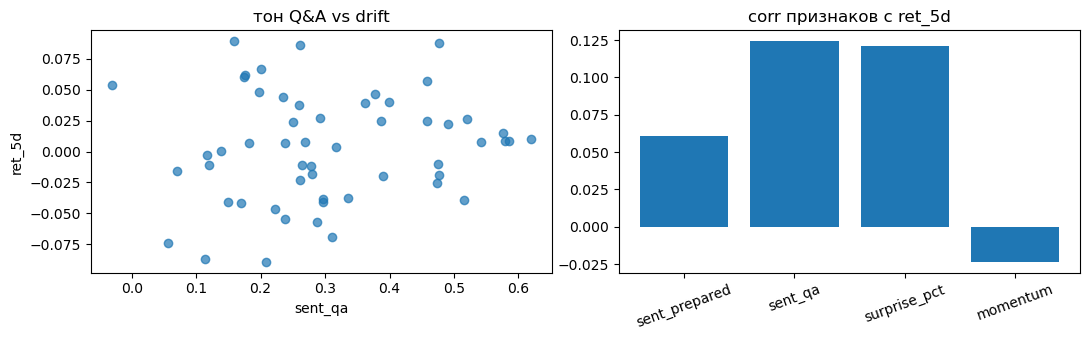

In [47]:
# смотрим простые связи признаков с ret_5d

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].scatter(df.sent_qa, df.ret_5d, alpha=0.7)
axes[0].set_xlabel("sent_qa"); axes[0].set_ylabel("ret_5d")
axes[0].set_title("тон Q&A vs drift")
corr = df[FEATURES + ["ret_5d"]].corr()["ret_5d"][:-1]
axes[1].bar(corr.index, corr.values)
axes[1].set_title("corr признаков с ret_5d")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

По scatter видно, что высокий `sent_qa` сам по себе не означает высокий `ret_5d`, потому что при похожем tone Q&A акция после отчета может и вырасти, и упасть

Корреляции небольшие, лучше всего выглядят `sent_qa` и `surprise_pct`, но связь все равно слабая

## Часть 3. Результаты

Три вопроса: какая компания/отрасль в нашей выборке предсказывается лучше, что добавляют текстовые признаки по сравнению с EPS surprise, и какую простую торговую стратегию можно построить на прогнозах модели.

### Out-of-fold предсказания

Один test split дает только 14 отчетов, этого мало для сравнения отраслей и ablation. Поэтому дальше используем `TimeSeriesSplit`. В каждом fold модель учится на прошлых отчетах и прогнозирует следующий кусок по времени. Так получается больше out-of-fold прогнозов

In [48]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit

# прогнозируем только будущие fold, не тот же train

def oof_predictions(feature_cols):
    proba = pd.Series(np.nan, index=df.index)
    for tr_idx, te_idx in TimeSeriesSplit(n_splits=5).split(df):
        # scaler и logreg заново учатся внутри каждого fold
        model = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED))
        model.fit(df.loc[tr_idx, feature_cols], df.loc[tr_idx, "y"])
        proba.iloc[te_idx] = model.predict_proba(df.loc[te_idx, feature_cols])[:, 1]
    return proba

proba_full = oof_predictions(FEATURES)
oof = df[proba_full.notna()].copy()
oof["proba"] = proba_full.dropna()
oof["pred"] = (oof.proba > 0.5).astype(int)
print(len(oof), "out-of-fold предсказаний")

45 out-of-fold предсказаний


45 out-of-fold прогнозов, дальше по ним считаем отрасли, ablation и стратегию

### Вопрос 1. Какая отрасль предсказуемее

In [49]:
q1 = (oof.groupby(["industry", "ticker"]) # метрики отдельно по каждой компании
      .apply(lambda g: pd.Series({
          "n": len(g),
          "accuracy": accuracy_score(g.y, g.pred),
          "roc_auc": roc_auc_score(g.y, g.proba) if g.y.nunique() > 1 else np.nan}))
      .round(3))
q1.sort_values("accuracy", ascending=False)

,,n,accuracy,roc_auc
industry,ticker,,,
Healthcare,JNJ,15.0,0.800,0.660
Industrials,CAT,15.0,0.600,0.589
Technology,AAPL,15.0,0.533,0.536


Лучше всего модель сработала на JNJ, там accuracy 0.80 и ROC-AUC 0.66. У CAT результат средний, у AAPL почти около случайного уровня

Поэтому в нашей выборке healthcare выглядит лучше остальных, но это фактически вывод по JNJ, потому что на каждую отрасль по одному тикеру

### Вопрос 2. Ablation

Берем одну и ту же logreg и меняем набор признаков. Так видно, что дают текст, EPS surprise и momentum отдельно и вместе

In [50]:
SUBSETS = {
    "full_model": FEATURES,
    "surprise_only": ["surprise_pct"],
    "without_text": ["surprise_pct", "momentum"],
    "text_only": ["sent_prepared", "sent_qa"],
}

# заранее считаем прогнозы для каждого набора признаков
ablation_proba = {
    name: oof_predictions(cols).loc[oof.index]
    for name, cols in SUBSETS.items()
}

# baseline тоже считаем по fold, majority class берем только из train
def oof_naive_baseline():
    pred = pd.Series(np.nan, index=df.index)
    for tr_idx, te_idx in TimeSeriesSplit(n_splits=5).split(df):
        majority_class = df.iloc[tr_idx]["y"].mode()[0]
        pred.iloc[te_idx] = majority_class
    return pred.loc[oof.index]

naive_oof = oof_naive_baseline()

def evaluate_data_impact(ticker=None):
    mask = oof.ticker == ticker if ticker else pd.Series(True, index=oof.index)
    y_true = oof.loc[mask, "y"]

    out = {}
    for name, proba in ablation_proba.items():
        out[name] = round(accuracy_score(y_true, proba.loc[mask] > 0.5), 2)

    out["naive_baseline"] = round(accuracy_score(y_true, naive_oof.loc[mask]), 2)
    return out

results = {"All": evaluate_data_impact()}
for t in sorted(df.ticker.unique()):
    results[t] = evaluate_data_impact(t)
pd.DataFrame(results).T

,full_model,surprise_only,without_text,text_only,naive_baseline
All,0.64,0.47,0.56,0.58,0.56
AAPL,0.53,0.53,0.53,0.60,0.53
CAT,0.60,0.47,0.47,0.47,0.47
JNJ,0.80,0.40,0.67,0.67,0.67


В среднем по всем компаниям full model дает лучший результат, accuracy 0.64 против 0.56 у naive baseline. `surprise_only` почти не работает, там 0.47, а `text_only` дает 0.58 и тоже обгоняет baseline

По компаниям результат разный. Для AAPL full model не добавляет качества к baseline, но `text_only` выглядит лучше остальных. Для CAT нормально работает только full model. Для JNJ full model тоже самый сильный, хотя вариант без текста и text only уже дают 0.67

Получается, EPS surprise сам по себе слабый сигнал в этой выборке. Текстовые признаки выглядят полезнее, но лучший общий результат получается, когда текст, EPS surprise и momentum используются вместе

### Вопрос 3. Торговая стратегия

Модель дает вероятность роста. Если p > 0.55 - покупаем на закрытии первого дня реакции и держим 4 дня; если p < 0.45 - шортим; иначе не торгуем.

Вход по закрытию дня T, когда прогноз уже можно было сделать. Доходность стратегии считаем от close(T) до close(T+4). Для сравнения также смотрим вариант после простых издержек.


In [51]:
def tradeable_return(ticker, reaction_day, hold=4):
    s = prices[ticker].dropna()
    i = s.index.get_loc(reaction_day)
    if i + hold >= len(s):
        return np.nan
    return float(s.iloc[i + hold] / s.iloc[i] - 1)

ROUNDTRIP_COST = 0.001  # грубо 10 bps на сделку

oof["ret_trade"] = oof.apply(lambda r: tradeable_return(r.ticker, r.reaction_day), axis=1)
# p выше 0.55 это long, ниже 0.45 это short, между ними пропускаем
oof["position"] = np.where(oof.proba > 0.55, 1, np.where(oof.proba < 0.45, -1, 0))
oof["pnl_gross"] = oof.position * oof.ret_trade
oof["pnl_net"] = np.where(oof.position != 0, oof.pnl_gross - ROUNDTRIP_COST, np.nan)

trades = oof[oof.position != 0].dropna(subset=["pnl_gross", "pnl_net"])
print("сделок:", len(trades), "из", len(oof), "out-of-fold отчетов")
print("hit rate:", round((trades.pnl_gross > 0).mean(), 2))
print("средняя доходность на сделку до издержек:", round(trades.pnl_gross.mean() * 100, 2), "%")
print("средняя доходность на сделку после издержек:", round(trades.pnl_net.mean() * 100, 2), "%")
print("суммарно до издержек:", round(trades.pnl_gross.sum() * 100, 1), "%")
print("суммарно после издержек:", round(trades.pnl_net.sum() * 100, 1), "%")
print("compounded после издержек:", round(((1 + trades.pnl_net).prod() - 1) * 100, 1), "%")

# сравнение: просто покупать после каждого отчёта
bh = oof.dropna(subset=["ret_trade"]).copy()
bh["ret_trade_net"] = bh.ret_trade - ROUNDTRIP_COST
print()
print("baseline 'always long' до издержек:", round(bh.ret_trade.mean() * 100, 2), "% на сделку,",
      round(bh.ret_trade.sum() * 100, 1), "% суммарно")
print("baseline 'always long' после издержек:", round(bh.ret_trade_net.mean() * 100, 2), "% на сделку,",
      round(bh.ret_trade_net.sum() * 100, 1), "% суммарно")


сделок: 37 из 45 out-of-fold отчетов
hit rate: 0.57
средняя доходность на сделку до издержек: 0.59 %
средняя доходность на сделку после издержек: 0.49 %
суммарно до издержек: 21.9 %
суммарно после издержек: 18.2 %
compounded после издержек: 17.8 %

baseline 'always long' до издержек: 0.2 % на сделку, 8.9 % суммарно
baseline 'always long' после издержек: 0.1 % на сделку, 4.4 % суммарно


Стратегия торгует не каждый отчет, а 37 из 45 случаев. После издержек средняя доходность на сделку остается положительной, 0.49%, а compounded return получается 17.8%

Наш baseline “always long” заметно слабее, получает 4.4% суммарно после издержек против 18.2% у стратегии. Значит в этой выборке модель не просто повторяет общий рост после отчетов, а отбирает более удачные long/short сделки

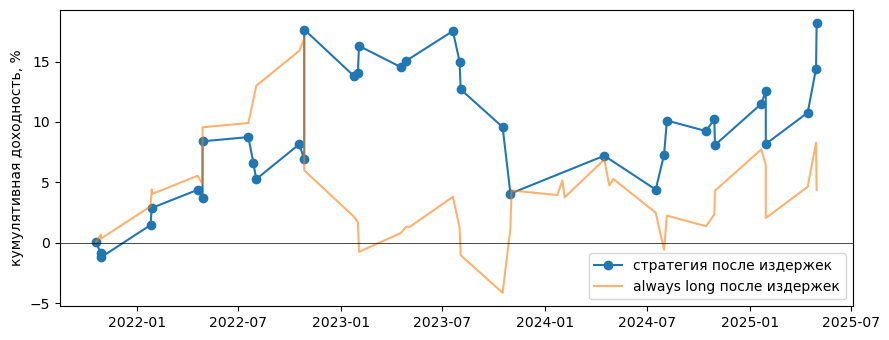

In [52]:
fig, ax = plt.subplots(figsize=(9, 3.5))
t = trades.sort_values("earn_date")
ax.plot(t.earn_date, t.pnl_net.cumsum() * 100, marker="o", label="стратегия после издержек")
b = bh.sort_values("earn_date")
ax.plot(b.earn_date, b.ret_trade_net.cumsum() * 100, alpha=0.6, label="always long после издержек")
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("кумулятивная доходность, %")
ax.legend(); plt.tight_layout(); plt.show()


На графике видно, что стратегия почти весь период идет выше baseline. У always long есть сильная просадка в 2023 году, а стратегия после этой точки остается в плюсе и заканчивает период заметно выше

Это совпадает с численным результатом выше, после издержек compounded return у стратегии 17.8%, а у always long суммарный результат только 4.4%. То есть модель не просто покупает рынок после отчетов, а меняет направление сделки в зависимости от прогноза

## Выводы

1. **Отрасли**: лучше всего в этой выборке предсказывается JNJ / Healthcare. У каждой компании всего 15 out-of-fold предсказаний, поэтому это скорее сравнение трех представителей, а не большой вывод по секторам.

2. **Ablation**: full model дает лучший общий accuracy. Surprise-only слабее, а текст менеджмента добавляет сигнал поверх EPS surprise, особенно через Q&A.

3. **Модель**: логистическая регрессия выглядит лучше для финального вывода. FCN оставляем как второй вариант из задания, но на такой маленькой выборке она легко переобучается.

4. **Стратегия**: торгуем только уверенные прогнозы, вход по закрытию дня реакции, горизонт 4 дня. После простых издержек стратегия все еще выше бейзлайна "всегда лонг", но это маленькая event-study выборка, а не готовая торговая система.

5. **Что можно улучшить**: расширить выборку по компаниям, секторам и годам, проверить другие горизонты после отчета и подобрать long/short thresholds на train, а не вручную.

Использовали ChatGPT: он помогал с поиском данных, загрузкой через Python, отладкой, отдельными кусками кода, графиками, выбором baseline/ablation и сверкой подхода с идеями из лекций и семинаров. Также помогал формулировать markdown-секции. Финальную логику, результаты, проверки на look-ahead bias, интерпретацию метрик и выводы мы проходили сами и правили руками